device: mps
checkpoint: models/resnet152_progressive.pth
validation images: 1303 of 6516 in data/ (20% holdout, seed 42)
accuracy: 0.882

painter                  support correct accuracy
Sandro Botticelli             29      29    1.000
Vincent van Gogh             182     175    0.962
Rembrandt                     50      48    0.960
Albrecht Durer                61      58    0.951
Kazimir Malevich              30      28    0.933
Peter Paul Rubens             25      23    0.920
Alfred Sisley                 48      44    0.917
Andy Warhol                   36      33    0.917
Amedeo Modigliani             47      43    0.915
Pieter Bruegel                31      28    0.903
Edgar Degas                  131     118    0.901
Francisco Goya                51      45    0.882
Paul Klee                     33      29    0.879
Paul Gauguin                  74      64    0.865
Pierre-Auguste Renoir         73      63    0.863
Hieronymus Bosch              26      22    0.846
Rene Magritt

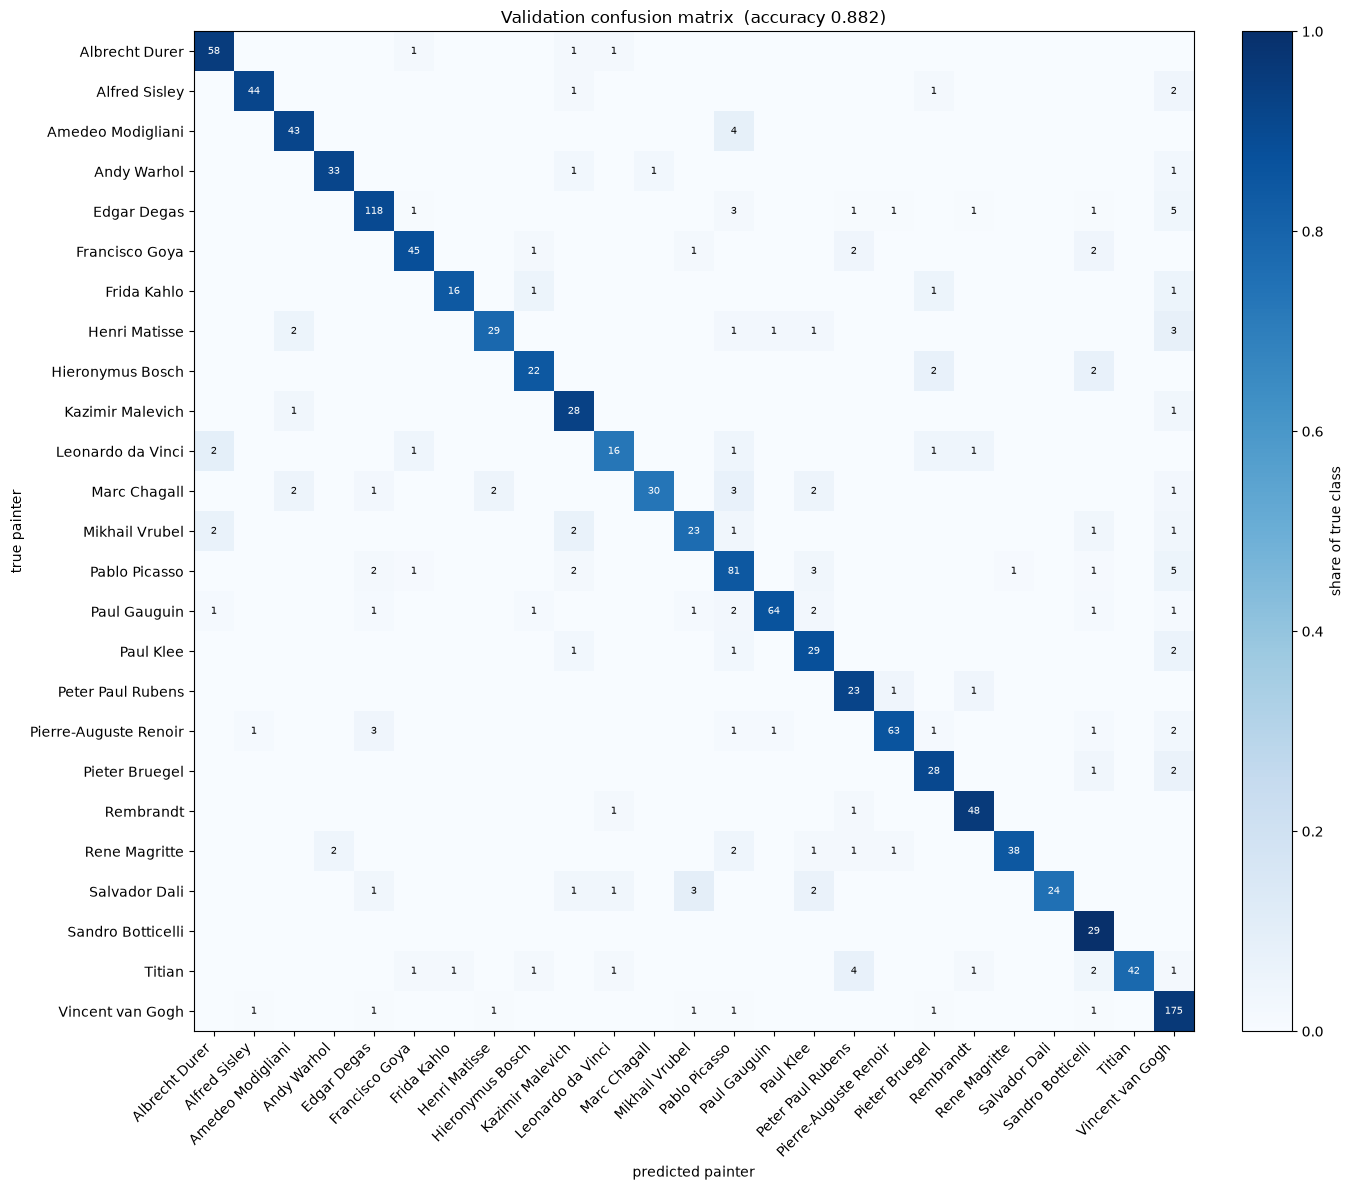

In [6]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, models, transforms

DATA_DIR = "data"
CHECKPOINT = "models/resnet152_progressive.pth"
BATCH_SIZE = 32
IMAGE_SIZE = 224

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Same validation geometry used while this checkpoint was trained.
eval_transform = transforms.Compose(
    [
        transforms.Resize(248),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)


class NumericImageFolder(datasets.ImageFolder):
    """ImageFolder that uses the numeric folder name as the class index."""

    def find_classes(self, directory):
        classes = [
            entry.name
            for entry in os.scandir(directory)
            if entry.is_dir() and entry.name.isdigit()
        ]
        classes.sort(key=int)
        class_to_idx = {name: int(name) for name in classes}
        return classes, class_to_idx


class TransformSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, index):
        image, label = self.subset[index]
        return self.transform(image), label


def painter_names(root):
    names = {}
    for class_dir in Path(root).iterdir():
        if not class_dir.is_dir() or not class_dir.name.isdigit():
            continue
        sample = next(
            path
            for path in class_dir.iterdir()
            if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        names[int(class_dir.name)] = sample.stem.rsplit("_", 1)[0]
    return dict(sorted(names.items()))


base_dataset = NumericImageFolder(DATA_DIR)
val_size = int(0.2 * len(base_dataset))
train_size = len(base_dataset) - val_size
_, val_base = random_split(
    base_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)
val_set = TransformSubset(val_base, eval_transform)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)

num_classes = len(base_dataset.classes)
painters = painter_names(DATA_DIR)
labels = [painters[i].replace("_", " ") for i in range(num_classes)]

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

model = models.resnet152(weights=None)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model.load_state_dict(torch.load(CHECKPOINT, map_location="cpu", weights_only=True))
model.to(device)
model.eval()

y_true = []
y_pred = []
y_pred_probs = []

with torch.no_grad():
    for images, batch_labels in val_loader:
        y_pred_prob = model(images.to(device)).cpu()
        y_pred_probs.append(y_pred_prob.softmax(dim=1))
        preds = y_pred_prob.argmax(dim=1).cpu()
        y_true.append(batch_labels)
        y_pred.append(preds)

y_true = torch.cat(y_true).numpy()
y_pred = torch.cat(y_pred).numpy()
accuracy = (y_true == y_pred).mean()

confusion = np.zeros((num_classes, num_classes), dtype=int)
for true_id, pred_id in zip(y_true, y_pred):
    confusion[true_id, pred_id] += 1

support = confusion.sum(axis=1)
correct = np.diag(confusion)
recall = np.divide(correct, support, out=np.zeros(num_classes), where=support > 0)

print(f"device: {device}")
print(f"checkpoint: {CHECKPOINT}")
print(
    f"validation images: {len(val_set)} of {len(base_dataset)} in {DATA_DIR}/ "
    f"(20% holdout, seed 42)"
)
print(f"accuracy: {accuracy:.3f}")
print()
print(f"{'painter':<24} {'support':>7} {'correct':>7} {'accuracy':>8}")
for class_id in np.argsort(-recall):
    print(
        f"{labels[class_id]:<24} {support[class_id]:7d} {correct[class_id]:7d} "
        f"{recall[class_id]:8.3f}"
    )

perfect = [labels[i] for i in range(num_classes) if support[i] > 0 and recall[i] == 1]
weak = [
    (labels[i], recall[i], int(support[i]))
    for i in np.argsort(recall)
    if support[i] > 0 and recall[i] < 0.8
]
print()
print("perfect:", ", ".join(perfect) if perfect else "none")
print("below 0.80:")
for name, score, count in weak:
    print(f"  {name}: {score:.3f} ({count} images)")

mistakes = []
for true_id in range(num_classes):
    for pred_id in range(num_classes):
        if true_id != pred_id and confusion[true_id, pred_id] > 0:
            mistakes.append((confusion[true_id, pred_id], labels[true_id], labels[pred_id]))
mistakes.sort(reverse=True)
print()
print("most common confusions (true -> predicted):")
for count, true_name, pred_name in mistakes[:8]:
    print(f"  {count:3d}  {true_name} -> {pred_name}")

row_sum = support[:, None]
normalized = np.divide(confusion, row_sum, out=np.zeros_like(confusion, dtype=float), where=row_sum > 0)

fig, ax = plt.subplots(figsize=(14, 12))
image = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(num_classes))
ax.set_yticks(range(num_classes))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
ax.set_xlabel("predicted painter")
ax.set_ylabel("true painter")
ax.set_title(f"Validation confusion matrix  (accuracy {accuracy:.3f})")
for true_id in range(num_classes):
    for pred_id in range(num_classes):
        count = confusion[true_id, pred_id]
        if count == 0:
            continue
        color = "white" if normalized[true_id, pred_id] > 0.5 else "black"
        ax.text(pred_id, true_id, str(count), ha="center", va="center", color=color, fontsize=7)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="share of true class")
fig.tight_layout()
fig.savefig("confusion_matrix_resnet152_progressive.png", dpi=150, bbox_inches="tight")
plt.show()

model.cpu()
if device.type == "mps":
    torch.mps.empty_cache()




In [7]:
y_pred

array([24, 14, 17, ...,  5, 24, 15], shape=(1303,))

In [8]:
CONFIDENT = 0.8

probabilities = torch.cat(y_pred_probs).numpy()
confidence = probabilities.max(axis=1)
true_confidence = probabilities[np.arange(len(y_true)), y_true]
wrong = y_true != y_pred
confident_wrong = wrong & (confidence >= CONFIDENT)
uncertain_wrong = wrong & (confidence < CONFIDENT)

print(f"wrong predictions: {wrong.sum()} / {len(y_true)}")
print(f"confidently wrong (p >= {CONFIDENT:.2f}): {confident_wrong.sum()}")
print(f"not confident (p < {CONFIDENT:.2f}): {uncertain_wrong.sum()}")
if uncertain_wrong.any():
    uncertain_mean = confidence[uncertain_wrong].mean()
else:
    uncertain_mean = float("nan")
if confident_wrong.any():
    confident_mean = confidence[confident_wrong].mean()
else:
    confident_mean = float("nan")
print(
    f"mean confidence on those mistakes: "
    f"confident {confident_mean:.3f}   not confident {uncertain_mean:.3f}"
)


def print_mistakes(mask, title):
    order = np.argsort(-confidence[mask])
    indices = np.flatnonzero(mask)[order]
    print()
    print(title)
    print(f"{'true':<24} {'predicted':<24} {'p(pred)':>8} {'p(true)':>8}")
    for index in indices:
        print(
            f"{labels[y_true[index]]:<24} {labels[y_pred[index]]:<24} "
            f"{confidence[index]:8.3f} {true_confidence[index]:8.3f}"
        )


print_mistakes(confident_wrong, "confidently wrong")
print_mistakes(uncertain_wrong, "wrong, but not confident")

wrong predictions: 154 / 1303
confidently wrong (p >= 0.80): 99
not confident (p < 0.80): 55
mean confidence on those mistakes: confident 0.953   not confident 0.607

confidently wrong
true                     predicted                 p(pred)  p(true)
Francisco Goya           Peter Paul Rubens           1.000    0.000
Pierre-Auguste Renoir    Sandro Botticelli           1.000    0.000
Pablo Picasso            Vincent van Gogh            1.000    0.000
Paul Gauguin             Pablo Picasso               1.000    0.000
Vincent van Gogh         Henri Matisse               1.000    0.000
Marc Chagall             Pablo Picasso               1.000    0.000
Pablo Picasso            Edgar Degas                 1.000    0.000
Pablo Picasso            Kazimir Malevich            1.000    0.000
Francisco Goya           Mikhail Vrubel              1.000    0.000
Paul Gauguin             Paul Klee                   1.000    0.000
Marc Chagall             Amedeo Modigliani           1.000    0.000

In [9]:
from sklearn.metrics import roc_curve

probabilities = torch.cat(y_pred_probs).numpy()

for class_id, name in enumerate(labels):
    scores = probabilities[:, class_id]
    positive = y_true == class_id
    fpr, tpr, thresholds = roc_curve(positive, scores)
    best = (tpr - fpr).argmax()
    print(f"{name:<24} threshold {thresholds[best]:.3f}  "
          f"TPR {tpr[best]:.3f}  FPR {fpr[best]:.3f}")

Albrecht Durer           threshold 0.022  TPR 1.000  FPR 0.007
Alfred Sisley            threshold 0.000  TPR 0.979  FPR 0.025
Amedeo Modigliani        threshold 0.013  TPR 0.979  FPR 0.016
Andy Warhol              threshold 0.000  TPR 1.000  FPR 0.032
Edgar Degas              threshold 0.009  TPR 0.977  FPR 0.022
Francisco Goya           threshold 0.003  TPR 0.941  FPR 0.030
Frida Kahlo              threshold 0.000  TPR 1.000  FPR 0.023
Henri Matisse            threshold 0.000  TPR 0.946  FPR 0.030
Hieronymus Bosch         threshold 0.010  TPR 1.000  FPR 0.016
Kazimir Malevich         threshold 0.205  TPR 0.967  FPR 0.010
Leonardo da Vinci        threshold 0.028  TPR 0.864  FPR 0.008
Marc Chagall             threshold 0.000  TPR 0.951  FPR 0.043
Mikhail Vrubel           threshold 0.000  TPR 1.000  FPR 0.101
Pablo Picasso            threshold 0.004  TPR 0.948  FPR 0.075
Paul Gauguin             threshold 0.002  TPR 0.959  FPR 0.023
Paul Klee                threshold 0.019  TPR 0.970  FP

train images: 5213
painter                    count    share
Vincent van Gogh             695    13.3%
Edgar Degas                  571    11.0%
Pablo Picasso                343     6.6%
Albrecht Durer               267     5.1%
Pierre-Auguste Renoir        263     5.0%
Francisco Goya               240     4.6%
Paul Gauguin                 237     4.5%
Rembrandt                    212     4.1%
Alfred Sisley                211     4.0%
Titian                       201     3.9%
Marc Chagall                 198     3.8%
Paul Klee                    155     3.0%
Rene Magritte                149     2.9%
Henri Matisse                149     2.9%
Amedeo Modigliani            146     2.8%
Andy Warhol                  145     2.8%
Mikhail Vrubel               141     2.7%
Sandro Botticelli            135     2.6%
Leonardo da Vinci            121     2.3%
Peter Paul Rubens            116     2.2%
Hieronymus Bosch             111     2.1%
Salvador Dali                107     2.1%
Pieter Bruegel 

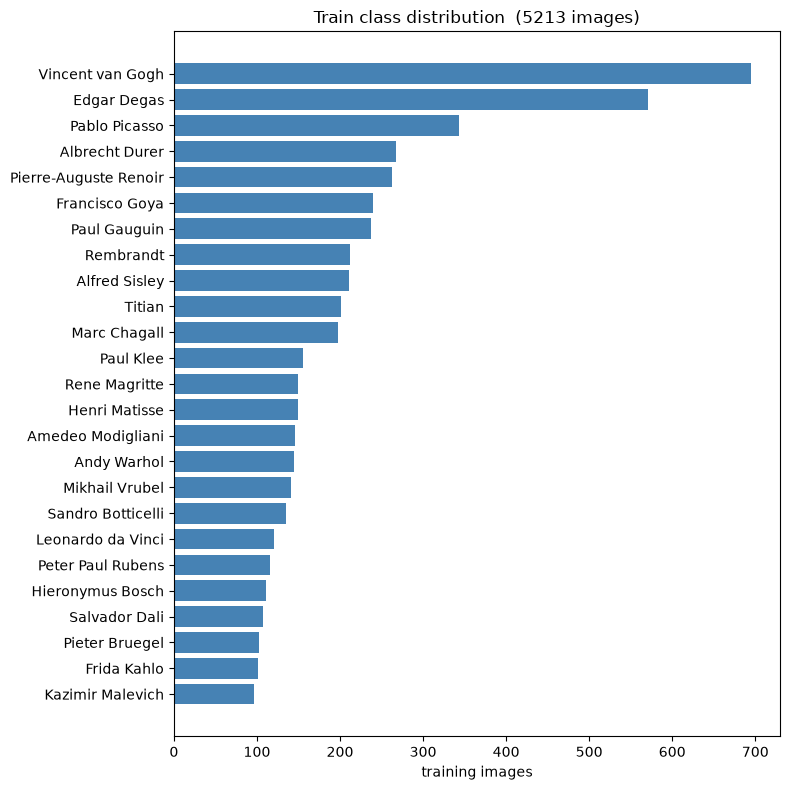

In [10]:
train_base, _ = random_split(
    base_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)
train_counts = np.bincount(
    [base_dataset.targets[index] for index in train_base.indices],
    minlength=num_classes,
)
train_share = train_counts / train_counts.sum()

print(f"train images: {int(train_counts.sum())}")
print(f"{'painter':<24} {'count':>7} {'share':>8}")
for class_id in np.argsort(-train_counts):
    print(
        f"{labels[class_id]:<24} {train_counts[class_id]:7d} "
        f"{train_share[class_id]:8.1%}"
    )

order = np.argsort(train_counts)
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(range(num_classes), train_counts[order], color="steelblue")
ax.set_yticks(range(num_classes))
ax.set_yticklabels([labels[i] for i in order])
ax.set_xlabel("training images")
ax.set_title(f"Train class distribution  ({int(train_counts.sum())} images)")
fig.tight_layout()
plt.show()


In [ ]:
import copy
import time

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

MAX_EPOCHS = 100
INITIAL_LR = 1e-3
STRAT_BATCH_SIZE = 32
LR_PATIENCE = 10
LR_FACTOR = 0.1
EARLY_STOP_PATIENCE = 30
OUTPUT_PATH = "models/resnet152_progressive_stratified.pth"
METRIC_NAMES = ("loss", "accuracy", "precision", "recall", "f1")

# Same small geometric augmentation used to train the loaded checkpoint.
train_transform = transforms.Compose(
    [
        transforms.Resize(248),
        transforms.RandomAffine(
            degrees=8,
            scale=(0.94, 1.06),
            interpolation=transforms.InterpolationMode.BILINEAR,
        ),
        transforms.RandomCrop(IMAGE_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

train_idx, val_idx = train_test_split(
    np.arange(len(base_dataset)),
    test_size=0.2,
    random_state=42,
    stratify=base_dataset.targets,
)
train_set = TransformSubset(Subset(base_dataset, train_idx), train_transform)
strat_val_set = TransformSubset(Subset(base_dataset, val_idx), eval_transform)
train_loader = DataLoader(train_set, batch_size=STRAT_BATCH_SIZE, shuffle=True)
strat_val_loader = DataLoader(strat_val_set, batch_size=STRAT_BATCH_SIZE, shuffle=False)

train_counts = np.bincount(
    [base_dataset.targets[index] for index in train_idx], minlength=num_classes
)
val_counts = np.bincount(
    [base_dataset.targets[index] for index in val_idx], minlength=num_classes
)
print(f"stratified train: {len(train_idx)}   validation: {len(val_idx)}")
print(f"{'painter':<24} {'train':>7} {'val':>7} {'val%':>7}")
for class_id in range(num_classes):
    share = val_counts[class_id] / (train_counts[class_id] + val_counts[class_id])
    print(f"{labels[class_id]:<24} {train_counts[class_id]:7d} {val_counts[class_id]:7d} {share:7.1%}")


def classification_metrics(y_true, y_pred):
    score_args = dict(
        average="macro",
        labels=list(range(num_classes)),
        zero_division=0,
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, **score_args),
        "recall": recall_score(y_true, y_pred, **score_args),
        "f1": f1_score(y_true, y_pred, **score_args),
    }


def run_epoch(net, loader, optimizer=None):
    training = optimizer is not None
    net.train(training)
    total_loss = 0.0
    total = 0
    true_all = []
    pred_all = []
    for images, batch_labels in loader:
        images = images.to(device)
        batch_labels = batch_labels.to(device)
        if training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = net(images)
            loss = torch.nn.functional.cross_entropy(logits, batch_labels)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * batch_labels.size(0)
        total += batch_labels.size(0)
        true_all.append(batch_labels.cpu())
        pred_all.append(logits.argmax(dim=1).cpu())
    y_true_epoch = torch.cat(true_all).numpy()
    y_pred_epoch = torch.cat(pred_all).numpy()
    metrics = classification_metrics(y_true_epoch, y_pred_epoch)
    metrics["loss"] = total_loss / total
    return metrics


def format_metrics(metrics):
    return (
        f"loss {metrics['loss']:.3f}  "
        f"acc {metrics['accuracy']:.3f}  "
        f"prec {metrics['precision']:.3f}  "
        f"rec {metrics['recall']:.3f}  "
        f"f1 {metrics['f1']:.3f}"
    )


model.load_state_dict(torch.load(CHECKPOINT, map_location="cpu", weights_only=True))
for param in model.parameters():
    param.requires_grad = True
model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=INITIAL_LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
)

history = {split: {name: [] for name in METRIC_NAMES} for split in ("train", "val")}
best_acc = -1.0
best_epoch = 0
best_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    started = time.time()
    lr = optimizer.param_groups[0]["lr"]
    train_metrics = run_epoch(model, train_loader, optimizer)
    val_metrics = run_epoch(model, strat_val_loader)
    for name in METRIC_NAMES:
        history["train"][name].append(train_metrics[name])
        history["val"][name].append(val_metrics[name])
    print(
        f"epoch {epoch:03d}/{MAX_EPOCHS}  lr {lr:.1e}  "
        f"train {format_metrics(train_metrics)}  "
        f"val {format_metrics(val_metrics)}  "
        f"({time.time() - started:.0f}s)",
        flush=True,
    )

    scheduler.step(val_metrics["accuracy"])
    lr_after = optimizer.param_groups[0]["lr"]
    if lr_after < lr:
        print(f"no val accuracy improvement for {LR_PATIENCE} epochs, lr -> {lr_after:.1e}", flush=True)

    if val_metrics["accuracy"] > best_acc:
        best_acc = val_metrics["accuracy"]
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
        continue

    epochs_without_improvement += 1
    if epochs_without_improvement >= EARLY_STOP_PATIENCE:
        print(
            f"stopping at epoch {epoch}: {epochs_without_improvement} epochs without val accuracy improvement",
            flush=True,
        )
        break

model.load_state_dict(best_state)
torch.save(model.state_dict(), OUTPUT_PATH)
print(
    f"saved {OUTPUT_PATH}  best val accuracy {best_acc:.3f} at epoch {best_epoch}",
    flush=True,
)

curve_names = [
    ("loss", "loss"),
    ("accuracy", "accuracy"),
    ("precision", "precision (macro)"),
    ("recall", "recall (macro)"),
    ("f1", "f1 (macro)"),
]
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for ax, (key, title) in zip(axes.ravel(), curve_names):
    epochs = np.arange(1, len(history["train"][key]) + 1)
    ax.plot(epochs, history["train"][key], label="train")
    ax.plot(epochs, history["val"][key], label="validation")
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
axes.ravel()[-1].axis("off")
fig.tight_layout()
fig.savefig("training_curves_resnet152_stratified.png", dpi=150, bbox_inches="tight")
plt.show()


